# From scores to decisions

Calibration of the model scores and cost-based decision thresholds for logistic regression and the tuned LightGBM.

In [2]:
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

from fraud.data import load_train
from fraud.features import add_features
from fraud.models import make_lightgbm, make_logreg
from fraud.split import time_split

In [3]:
df = add_features(load_train())
train, valid, _ = time_split(df)

NON_FEATURES = ["isFraud", "TransactionDT", "TransactionID"]
X_train, y_train = train.drop(columns=NON_FEATURES), train["isFraud"]
X_valid, y_valid = valid.drop(columns=NON_FEATURES), valid["isFraud"]

LR_COLS = [c for c in X_train.columns if not c.startswith("V")]
CAT_COLS = X_train[LR_COLS].select_dtypes("category").columns.tolist()
NUM_COLS = [c for c in LR_COLS if c not in CAT_COLS]

logreg = make_logreg(NUM_COLS, CAT_COLS)
logreg.fit(X_train, y_train)

lgbm = make_lightgbm(seed=42, n_jobs=8)
lgbm.fit(X_train, y_train, eval_X=X_valid, eval_y=y_valid, callbacks=[lgb.early_stopping(100, verbose=False)])

SCORES = {
    "Logistic regression": logreg.predict_proba(X_valid)[:, 1],
    "LightGBM": lgbm.predict_proba(X_valid)[:, 1],
}

print(f"actual fraud share in valid: {y_valid.mean():.2%}")
for name, scores in SCORES.items():
    print(f"{name}: mean predicted {scores.mean():.2%}")

actual fraud share in valid: 3.41%
Logistic regression: mean predicted 5.30%
LightGBM: mean predicted 2.00%


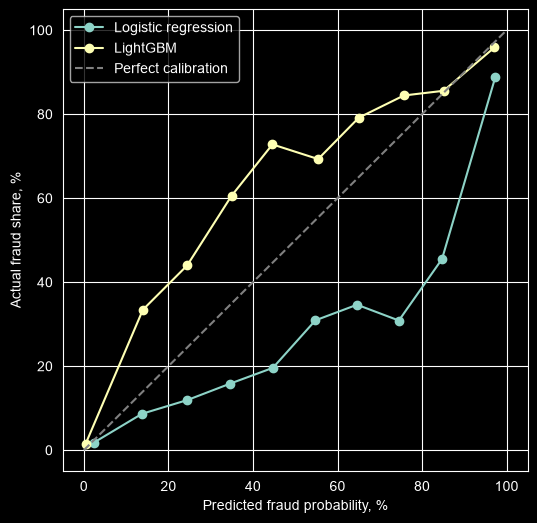

In [4]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
for name, scores in SCORES.items():
    actual, predicted = calibration_curve(y_valid, scores, n_bins=10)
    ax.plot(predicted * 100, actual * 100, marker="o", label=name)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Perfect calibration")
ax.set_xlabel("Predicted fraud probability, %")
ax.set_ylabel("Actual fraud share, %")
ax.legend()
plt.show()

**Calibration on valid.** Actual fraud share is 3.41%. Logistic regression overestimates (mean score 5.30%; at a score of 45% only about 20% are fraud). LightGBM underestimates (mean score 2.00%; at 25% about 44% are fraud, at 45% about 73%). Neither score can be read as a probability yet.

In [5]:
print(f"actual fraud share in train: {y_train.mean():.2%}")
print(f"Logistic regression: mean predicted {logreg.predict_proba(X_train)[:, 1].mean():.2%}")
print(f"LightGBM: mean predicted {lgbm.predict_proba(X_train)[:, 1].mean():.2%}")

actual fraud share in train: 3.52%
Logistic regression: mean predicted 3.52%
LightGBM: mean predicted 3.52%


**Calibration on train.** On the training months both models match the actual fraud share exactly (3.52%), while on valid they drift apart in opposite directions. The error appears only on new data, so the correction is learned on valid, not on train.

In [6]:
from sklearn.isotonic import IsotonicRegression
from fraud.split import SECONDS_PER_DAY, time_split

In [7]:
day = valid["TransactionDT"] // SECONDS_PER_DAY
calib_fit = (day < 136).to_numpy()
y_fit, y_check = y_valid[calib_fit], y_valid[~calib_fit]
print(f"fit: days {day[calib_fit].min()}-{day[calib_fit].max()}, fraud share {y_fit.mean():.2%}")
print(f"check: days {day[~calib_fit].min()}-{day[~calib_fit].max()}, fraud share {y_check.mean():.2%}")

fit: days 121-135, fraud share 3.55%
check: days 136-150, fraud share 3.25%


In [8]:
CALIBRATED = {}
for name, scores in SCORES.items():
    isotonic = IsotonicRegression(out_of_bounds="clip")
    isotonic.fit(scores[calib_fit], y_fit)
    CALIBRATED[name] = isotonic.predict(scores[~calib_fit])
    print(f"{name}: mean before {scores[~calib_fit].mean():.2%}, after {CALIBRATED[name].mean():.2%}")

Logistic regression: mean before 5.17%, after 3.30%
LightGBM: mean before 1.74%, after 3.20%


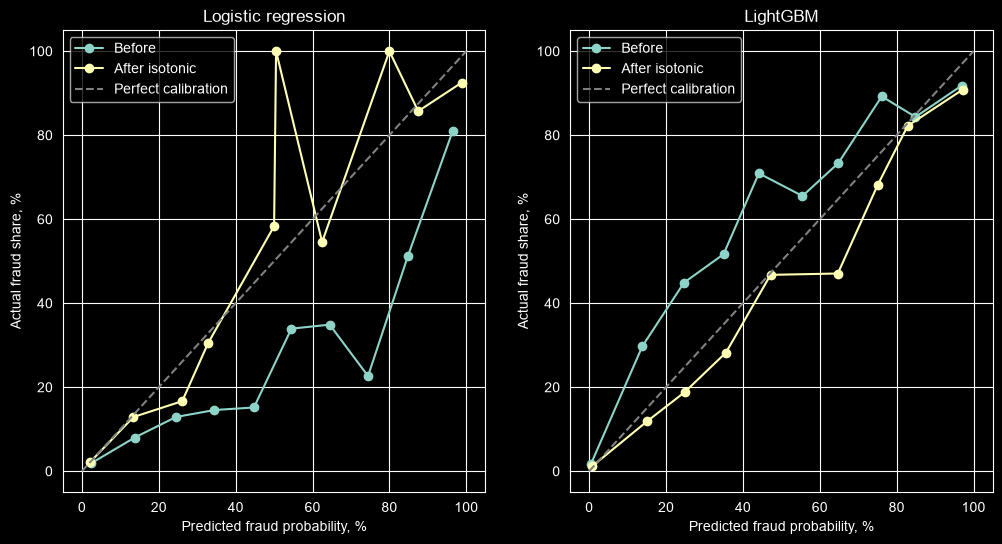

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (name, scores) in zip(axes, SCORES.items()):
    for label, probs in [("Before", scores[~calib_fit]), ("After isotonic", CALIBRATED[name])]:
        actual, predicted = calibration_curve(y_check, probs, n_bins=10)
        ax.plot(predicted * 100, actual * 100, marker="o", label=label)
    ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Perfect calibration")
    ax.set_title(name)
    ax.set_xlabel("Predicted fraud probability, %")
    ax.set_ylabel("Actual fraud share, %")
    ax.legend()
plt.show()

**Isotonic calibration, checked on days 136-150.** Fitted on days 121-135, it brings both models close to the diagonal at low scores, where most transactions are. Higher up the points jump: those bins hold few transactions, and the isotonic steps learned there from few examples. LightGBM's mean now matches (3.20% vs 3.25%), but its middle bins are overestimated (35% → 28%), so the mean hides errors in both directions.

In [10]:
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

In [11]:
p = y_check.mean()
print(f"floor, always {p:.2%}: Brier {brier_score_loss(y_check, [p] * len(y_check)):.4f}")
for name, scores in SCORES.items():
    before, after = scores[~calib_fit], CALIBRATED[name]
    print(f"{name}: Brier {brier_score_loss(y_check, before):.4f} -> {brier_score_loss(y_check, after):.4f}, "
          f"PR-AUC {average_precision_score(y_check, before):.4f} -> {average_precision_score(y_check, after):.4f}")

floor, always 3.25%: Brier 0.0315
Logistic regression: Brier 0.0314 -> 0.0282, PR-AUC 0.2219 -> 0.2076
LightGBM: Brier 0.0212 -> 0.0203, PR-AUC 0.5516 -> 0.5362


In [12]:
from sklearn.linear_model import LogisticRegression

RAW = {
    "Logistic regression": logreg.decision_function(X_valid),
    "LightGBM": lgbm.predict(X_valid, raw_score=True),
}

PLATT = {}
for name, raw in RAW.items():
    platt = LogisticRegression()
    platt.fit(raw[calib_fit].reshape(-1, 1), y_fit)
    PLATT[name] = platt.predict_proba(raw[~calib_fit].reshape(-1, 1))[:, 1]
    print(f"{name}: mean {PLATT[name].mean():.2%}, Brier {brier_score_loss(y_check, PLATT[name]):.4f}, "
          f"PR-AUC {average_precision_score(y_check, PLATT[name]):.4f}")

Logistic regression: mean 3.30%, Brier 0.0283, PR-AUC 0.2219
LightGBM: mean 3.17%, Brier 0.0202, PR-AUC 0.5516


**Platt scaling on days 136–150.** Brier is the same as with isotonic (0.0283 vs 0.0282 for logistic regression, 0.0202 vs 0.0203 for LightGBM), but PR-AUC stays exactly as before (0.2219 and 0.5516): the S-curve only stretches and shifts the raw score, so the order of transactions is unchanged.

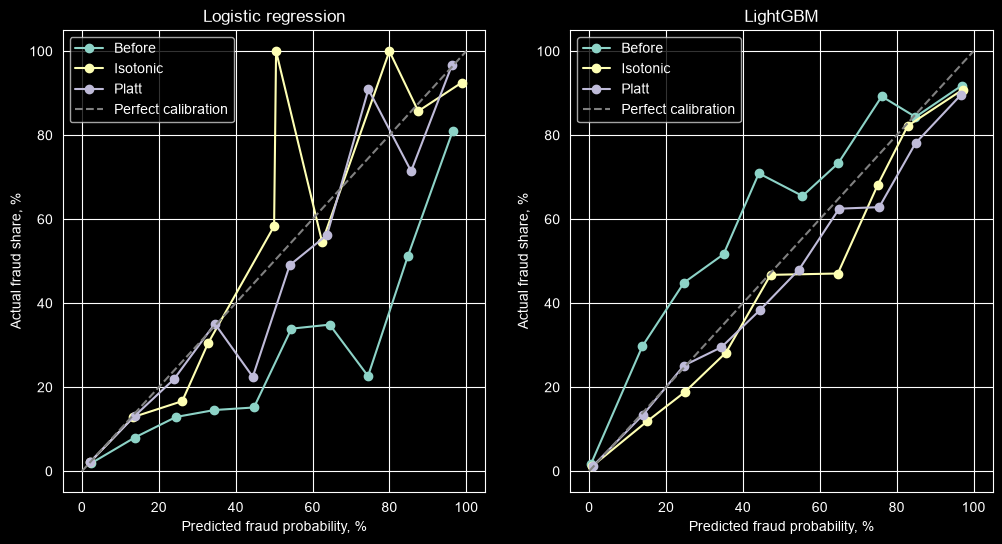

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (name, scores) in zip(axes, SCORES.items()):
    for label, probs in [("Before", scores[~calib_fit]), ("Isotonic", CALIBRATED[name]), ("Platt", PLATT[name])]:
        actual, predicted = calibration_curve(y_check, probs, n_bins=10)
        ax.plot(predicted * 100, actual * 100, marker="o", label=label)
    ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Perfect calibration")
    ax.set_title(name)
    ax.set_xlabel("Predicted fraud probability, %")
    ax.set_ylabel("Actual fraud share, %")
    ax.legend()
plt.show()

**Decision: Platt scaling.** It matches isotonic on Brier, keeps the order of transactions (no PR-AUC loss) and gives LightGBM a smooth curve close to the diagonal up to about 25%, slightly overestimating above 35% (by 5-10 points). The zigzags in the logistic regression curve come from bins with few transactions, not from the S-curve itself. Before the test run the S-curve is refit on all of valid (days 121-150), and again whenever the model changes.

## Cost of errors

Assumed costs: a missed fraud costs its amount plus a 20 chargeback fee; blocking an honest transaction costs 10 (lost fee and an annoyed customer). Caught fraud and approved honest transactions cost nothing. Money is counted on days 136-150, where the Platt probabilities were not fitted.

In [14]:
FRAUD_FEE = 20
DECLINE_COST = 10

amount = valid["TransactionAmt"].to_numpy()[~calib_fit]
fraud = y_check.to_numpy() == 1
print(f"days 136-150: {len(fraud)} transactions, {fraud.sum()} fraud, fraud amount ${amount[fraud].sum():,.0f}")
print(f"approve everything: loss ${(amount[fraud] + FRAUD_FEE).sum():,.0f}")
print(f"block everything: loss ${(~fraud).sum() * DECLINE_COST:,.0f}")

days 136-150: 39313 transactions, 1278 fraud, fraud amount $199,116
approve everything: loss $224,676
block everything: loss $380,350


Logistic regression: best threshold 4%, loss $150,127, saves $74,549 (33%) vs approving everything
LightGBM: best threshold 4%, loss $88,541, saves $136,135 (61%) vs approving everything


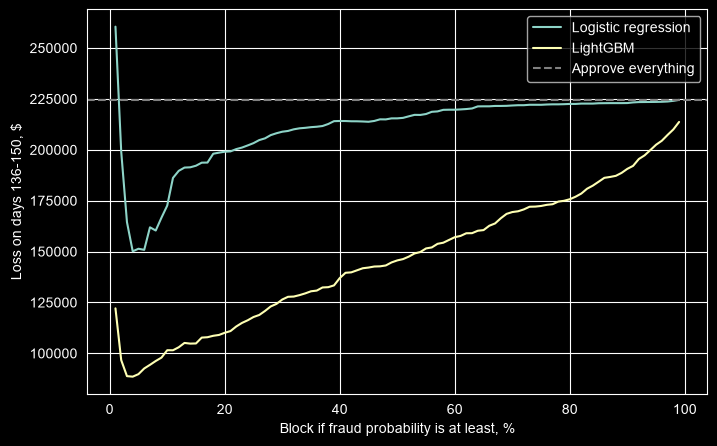

In [15]:
THRESHOLDS = list(range(1, 100))
approve_all = (amount[fraud] + FRAUD_FEE).sum()

fig, ax = plt.subplots(figsize=(8, 5))
for name, probs in PLATT.items():
    losses = []
    for t in THRESHOLDS:
        block = probs >= t / 100
        missed = fraud & ~block
        false_alarms = ~fraud & block
        losses.append((amount[missed] + FRAUD_FEE).sum() + false_alarms.sum() * DECLINE_COST)
    best = losses.index(min(losses))
    print(f"{name}: best threshold {THRESHOLDS[best]}%, loss ${losses[best]:,.0f}, "
          f"saves ${approve_all - losses[best]:,.0f} ({1 - losses[best] / approve_all:.0%}) vs approving everything")
    ax.plot(THRESHOLDS, losses, label=name)
ax.axhline(approve_all, color="gray", linestyle="--", label="Approve everything")
ax.set_xlabel("Block if fraud probability is at least, %")
ax.set_ylabel("Loss on days 136-150, $")
ax.legend()
plt.show()

Blocking every transaction with a fraud probability of at least 4% is the cheapest single threshold for both models. LightGBM then loses 88,541 instead of 224,676 (61% saved), logistic regression 150,127 (33% saved). The intuitive 50% threshold would cost LightGBM about 147,000: a missed fraud costs about 176 on average and a false alarm 10, so blocking pays off already at a few percent. The threshold is chosen on the same days it is measured on, so these savings are slightly optimistic; the final check is on test.

In [16]:
for name, probs in PLATT.items():
    rules = {
        "threshold 4%": probs >= 0.04,
        "expected loss": probs * (amount + FRAUD_FEE) > (1 - probs) * DECLINE_COST,
    }
    for rule, block in rules.items():
        missed = fraud & ~block
        false_alarms = ~fraud & block
        loss = (amount[missed] + FRAUD_FEE).sum() + false_alarms.sum() * DECLINE_COST
        print(f"{name}, {rule}: loss ${loss:,.0f} ({1 - loss / approve_all:.0%} saved), "
              f"{block.sum()} blocked, {false_alarms.sum()} of them honest")

Logistic regression, threshold 4%: loss $150,127 (33% saved), 8094 blocked, 7267 of them honest
Logistic regression, expected loss: loss $114,819 (49% saved), 4376 blocked, 3812 of them honest
LightGBM, threshold 4%: loss $88,541 (61% saved), 4378 blocked, 3402 of them honest
LightGBM, expected loss: loss $73,004 (68% saved), 3602 blocked, 2738 of them honest


Blocking a transaction when approving it is expected to cost more than blocking it (probability × (amount + USD 20) against (1 − probability) × USD 10) beats the single 4% threshold for both models on both counts. LightGBM loses USD 73,004 (68% saved) and blocks 2,738 honest transactions, against USD 88,541 and 3,402 with the threshold; logistic regression goes from 33% to 49% saved. The rule catches fewer frauds (864 vs 976 for LightGBM), but the ones it lets through are small: USD 90 on average against USD 161. It is not tuned on days 136-150, so its savings are not inflated like the threshold's. Two limits: letting small frauds through can confirm to a fraudster that a stolen card works, and 7.2% of honest customers are still blocked.

Third action: ask the customer to confirm the purchase, for example with a code sent by SMS. Assumed: it costs USD 2 per honest customer (some give up the purchase), and 10% of fraudsters still pass. Each transaction gets the action with the lowest expected cost.

In [17]:
VERIFY_COST = 2
VERIFY_PASS = 0.1

for name, probs in PLATT.items():
    approve_cost = probs * (amount + FRAUD_FEE)
    verify_cost = (1 - probs) * VERIFY_COST + probs * VERIFY_PASS * (amount + FRAUD_FEE)
    decline_cost = (1 - probs) * DECLINE_COST
    decline = (decline_cost < approve_cost) & (decline_cost < verify_cost)
    verify = ~decline & (verify_cost < approve_cost)
    approve = ~decline & ~verify
    loss = ((amount[fraud & approve] + FRAUD_FEE).sum()
            + VERIFY_PASS * (amount[fraud & verify] + FRAUD_FEE).sum()
            + VERIFY_COST * (~fraud & verify).sum()
            + DECLINE_COST * (~fraud & decline).sum())
    print(f"{name}: loss ${loss:,.0f} ({1 - loss / approve_all:.0%} saved); "
          f"declined {decline.sum()} ({(~fraud & decline).sum()} honest), "
          f"verified {verify.sum()} ({(~fraud & verify).sum()} honest)")

Logistic regression: loss $71,560 (68% saved); declined 406 (274 honest), verified 15961 (15074 honest)
LightGBM: loss $45,571 (80% saved); declined 1029 (449 honest), verified 7831 (7342 honest)


With a third action the loss drops further: LightGBM loses USD 45,571 (80% saved) and declines 449 honest customers instead of 2,738, but asks 7,342 honest customers (19% of them) to confirm. Logistic regression with three actions saves 68%, as much as LightGBM with two, so the decision rule matters as much as the model. The gain rests on the assumed USD 2 cost of a confirmation.

In [18]:
probs = PLATT["LightGBM"]
honest = ~fraud
for price in [1, 2, 5, 10]:
    approve_cost = probs * (amount + FRAUD_FEE)
    verify_cost = (1 - probs) * price + probs * VERIFY_PASS * (amount + FRAUD_FEE)
    decline_cost = (1 - probs) * DECLINE_COST
    decline = (decline_cost < approve_cost) & (decline_cost < verify_cost)
    verify = ~decline & (verify_cost < approve_cost)
    approve = ~decline & ~verify
    loss = ((amount[fraud & approve] + FRAUD_FEE).sum()
            + VERIFY_PASS * (amount[fraud & verify] + FRAUD_FEE).sum()
            + price * (honest & verify).sum()
            + DECLINE_COST * (honest & decline).sum())
    print(f"confirmation USD {price}: loss ${loss:,.0f} ({1 - loss / approve_all:.0%} saved); "
          f"honest declined {(honest & decline).sum()}, "
          f"honest asked to confirm {(honest & verify).sum()} ({(honest & verify).sum() / honest.sum():.0%})")

confirmation USD 1: loss $34,901 (84% saved); honest declined 400, honest asked to confirm 11088 (29%)
confirmation USD 2: loss $45,571 (80% saved); honest declined 449, honest asked to confirm 7342 (19%)
confirmation USD 5: loss $63,528 (72% saved); honest declined 682, honest asked to confirm 3629 (10%)
confirmation USD 10: loss $73,004 (68% saved); honest declined 2738, honest asked to confirm 0 (0%)


At USD 10 a confirmation costs as much as a decline but stops less fraud, so it is never chosen and the result equals the two-action rule exactly (USD 73,004, 2,738 honest customers declined), which also checks the code. At any lower price three actions beat two: from 72% saved at USD 5 to 84% at USD 1, with 400-682 honest customers declined instead of 2,738. What depends on the price is how many honest customers are asked to confirm: 10% at USD 5, 19% at USD 2, 29% at USD 1. Adding the third action is a safe decision; how often to use it has to be agreed with the business. USD 2 stays the main assumption.

In [19]:
from fraud.decisions import DECLINE_COST, choose_actions, total_loss

probs = PLATT["LightGBM"]
verify, decline = choose_actions(probs, amount)
print(f"three actions: loss ${total_loss(fraud, amount, verify, decline):,.0f}")
verify, decline = choose_actions(probs, amount, verify_cost=DECLINE_COST)
print(f"two actions: loss ${total_loss(fraud, amount, verify, decline, verify_cost=DECLINE_COST):,.0f}")

three actions: loss $45,571
two actions: loss $73,004


The decision rule now lives in `src/fraud/decisions.py` and reproduces the notebook results exactly (USD 45,571 with three actions, USD 73,004 with two), so test and the demo use the same code.